# 02 - Data Preprocessing

## Objective

Prepare the Unified Coastal Waste Dataset (UCWD)
for object detection model training.

This notebook addresses the issues identified during exploratory data analysis, particularly annotation boundary errors and temporal data leakage.

The original dataset will remain unchanged

## 1. Library imports

In [1]:
from pathlib import Path
from collections import Counter

import shutil
import random
import re
import yaml

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import GroupShuffleSplit

sns.set_theme(style="whitegrid")

# Ensure reproducibility
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

## 2. Dataset configuration

In [2]:
# Define project directory
PROJECT_DIR = Path(
    r"C:\Users\lenam\Documents\GitHub\plastic-waste-detection"
).resolve()

# Define raw and processed dataset paths
RAW_DIR = PROJECT_DIR / "data" / "raw" / "ucwd" / "UCWD.yolo"

PROCESSED_DIR = (
    PROJECT_DIR / "data" / "processed" / "ucwd_clean"
)

# Load original dataset configuration
with open(RAW_DIR / "data.yaml", "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

# Define dataset parameters
class_names = config["names"]
splits = ["train", "valid", "test"]

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

# Check paths and configuration
print("Raw dataset:", RAW_DIR)
print("Raw dataset exists:", RAW_DIR.exists())
print("Processed dataset:", PROCESSED_DIR)
print("Number of classes:", len(class_names))
print("Classes:", class_names)

Raw dataset: C:\Users\lenam\Documents\GitHub\plastic-waste-detection\data\raw\ucwd\UCWD.yolo
Raw dataset exists: True
Processed dataset: C:\Users\lenam\Documents\GitHub\plastic-waste-detection\data\processed\ucwd_clean
Number of classes: 7
Classes: ['Glass', 'Metal', 'Packet', 'Plastic bag', 'Plastic bottle', 'Plastic container', 'Plastic fragment']


## 3. Dataset inventory

Create a complete inventory of images and associated annotation files, preserving the original dataset split information for traceability.

In [3]:
# Build dataset inventory
records = []

for split in splits:

    images_dir = RAW_DIR / split / "images"
    labels_dir = RAW_DIR / split / "labels"

    for image_path in sorted(images_dir.iterdir()):

        if image_path.suffix.lower() not in image_extensions:
            continue

        label_path = labels_dir / f"{image_path.stem}.txt"

        records.append({
            "original_split": split,
            "filename": image_path.stem,
            "image_path": image_path,
            "label_path": label_path,
            "label_exists": label_path.exists()
        })

df_inventory = pd.DataFrame(records)

print("Total images:", len(df_inventory))
print("Missing labels:", (~df_inventory["label_exists"]).sum())

display(df_inventory.head())

Total images: 4071
Missing labels: 0


,original_split,filename,image_path,label_path,label_exists
0,train,batch_01_frame_0_jpg.rf.bc525bc8947e822be47291...,C:\Users\lenam\Documents\GitHub\plastic-waste-...,C:\Users\lenam\Documents\GitHub\plastic-waste-...,True
1,train,batch_01_frame_10_jpg.rf.7dd168b4bdcbeb7e02510...,C:\Users\lenam\Documents\GitHub\plastic-waste-...,C:\Users\lenam\Documents\GitHub\plastic-waste-...,True
2,train,batch_01_frame_11_jpg.rf.50a4d0a2020280a10efd6...,C:\Users\lenam\Documents\GitHub\plastic-waste-...,C:\Users\lenam\Documents\GitHub\plastic-waste-...,True
3,train,batch_01_frame_13_jpg.rf.008d14256c4d381b71efe...,C:\Users\lenam\Documents\GitHub\plastic-waste-...,C:\Users\lenam\Documents\GitHub\plastic-waste-...,True
4,train,batch_01_frame_15_jpg.rf.1a03b1cf484a3627a4484...,C:\Users\lenam\Documents\GitHub\plastic-waste-...,C:\Users\lenam\Documents\GitHub\plastic-waste-...,True


## 4. Annotation quality

The exploratory data analysis identified 91 bounding boxes with a negligible boundary overflow of 0.005 pixels and two subpixel annotations.

Given the limited magnitude of these anomalies,
the original annotations are retained without modification.

Preprocessing will primarily focus on mitigating
data leakage between dataset splits.

## 5. Acquisition group identification

### 5.1. Visual assessment of temporal data leakage

Compare temporally close frames from the same video
across the original training, validation and test
sets to assess visual similarities.

In [7]:
# Remove Roboflow suffixes
df_inventory["original_name"] = (
    df_inventory["filename"]
    .str.split(".rf.", regex=False)
    .str[0]
)

# Select video-derived images
df_video = df_inventory[
    df_inventory["original_name"]
    .str.contains(r"_MP4-\d+", case=False, regex=True)
].copy()

# Extract video identifiers
df_video["video_id"] = (
    df_video["original_name"]
    .str.replace(r"_MP4-\d+.*$", "", case=False, regex=True)
)

# Extract frame numbers
df_video["frame_number"] = (
    df_video["original_name"]
    .str.extract(r"_MP4-(\d+)", flags=re.IGNORECASE)[0]
    .astype(int)
)

display(
    df_video[
        ["original_split", "video_id", "frame_number"]
    ].head(10)
)

,original_split,video_id,frame_number
2200,train,VID_20230622_133111_0001,100
2201,train,VID_20230622_133111_0001,114
2202,train,VID_20230622_133111_0001,115
2203,train,VID_20230622_133111_0001,116
2204,train,VID_20230622_133111_0001,117
2205,train,VID_20230622_133111_0001,121
2206,train,VID_20230622_133111_0001,122
2207,train,VID_20230622_133111_0001,123
2208,train,VID_20230622_133111_0001,124
2209,train,VID_20230622_133111_0001,125


In [8]:
def compare_video_frames(video_id):

    # Select images from the same video
    video_images = df_video[
        df_video["video_id"] == video_id
    ]

    # Select validation frames
    valid_frames = video_images[
        video_images["original_split"] == "valid"
    ].sort_values("frame_number")

    # Select the middle validation frame
    reference = valid_frames.iloc[len(valid_frames) // 2]
    reference_frame = reference["frame_number"]

    fig, axes = plt.subplots(1, 3, figsize=(20, 8))

    for ax, split in zip(axes, ["train", "valid", "test"]):

        candidates = video_images[
            video_images["original_split"] == split
        ].copy()

        if candidates.empty:
            ax.set_title(f"{split}: No image")
            ax.axis("off")
            continue

        # Calculate distance from reference frame
        candidates["frame_distance"] = (
            candidates["frame_number"] - reference_frame
        ).abs()

        # Select the closest frame
        selected = candidates.loc[
            candidates["frame_distance"].idxmin()
        ]

        # Display image
        with Image.open(selected["image_path"]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"{split.upper()}\n"
            f"Frame {selected['frame_number']}\n"
            f"Distance: {selected['frame_distance']}"
        )

        ax.axis("off")

    fig.suptitle(video_id, fontsize=16)
    plt.tight_layout()
    plt.show()

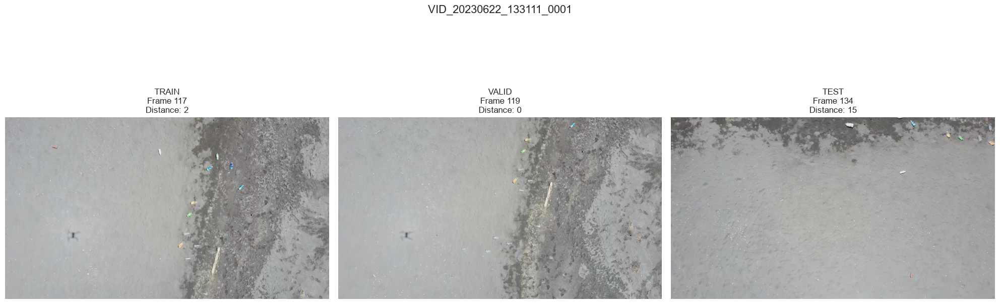

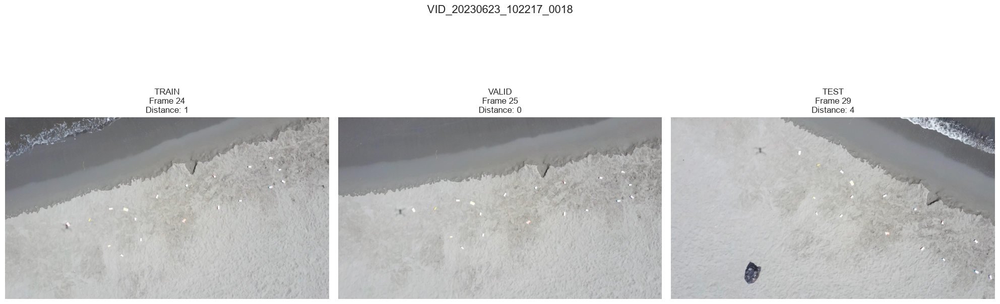

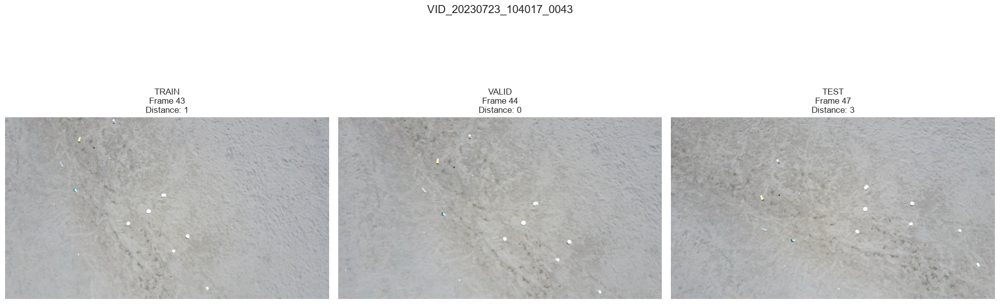

In [9]:
compare_video_frames("VID_20230622_133111_0001")
compare_video_frames("VID_20230623_102217_0018")
compare_video_frames("VID_20230723_104017_0043")

### Visual assessment results

Visual comparisons of frames from three video sequences revealed substantial spatial overlap between the original training, validation and test sets.

Several physical waste objects can be identified across multiple dataset splits, despite changes in camera position and orientation.

Although SHA-256 hashing detected no exact binary
duplicates, visual inspection confirmed that different images may contain the same physical objects.

These observations support the implementation of a
group-based splitting strategy to reduce temporal
and spatial data leakage and improve the reliability of model evaluation.

### 5.2. Filename pattern analysis

In [10]:
# Identify filename families
df_inventory["filename_prefix"] = (
    df_inventory["original_name"]
    .str.extract(r"^([A-Za-z]+)")[0]
    .str.upper()
    .fillna("OTHER")
)

# Count images by filename family
prefix_distribution = (
    df_inventory["filename_prefix"]
    .value_counts()
)

display(prefix_distribution)

filename_prefix
DJI       1200
VID       1151
CD         966
BATCH      712
GOPR        33
PHOTO        5
CAMERA       4
Name: count, dtype: int64

### 5.3. Detailed filename analysis

Investigate naming conventions within each image
family to identify potential acquisition groups
and define appropriate grouping rules.

In [11]:
# Inspect filename examples for each family
for prefix in prefix_distribution.index:

    subset = df_inventory[
        df_inventory["filename_prefix"] == prefix
    ]

    print(f"\n--- {prefix} ({len(subset)} images) ---")

    examples = (
        subset["original_name"]
        .drop_duplicates()
        .sort_values()
    )

    print(examples.head(15).to_string(index=False))


--- DJI (1200 images) ---
DJI_0001_JPG
DJI_0002_JPG
DJI_0003_JPG
DJI_0004_JPG
DJI_0005_JPG
DJI_0006_JPG
DJI_0007_JPG
DJI_0008_JPG
DJI_0009_JPG
DJI_0010_JPG
DJI_0011_JPG
DJI_0012_JPG
DJI_0013_JPG
DJI_0014_JPG
DJI_0015_JPG

--- VID (1151 images) ---
  VID_20230622_133111_0001_MP4-0_jpg
VID_20230622_133111_0001_MP4-100_jpg
VID_20230622_133111_0001_MP4-110_jpg
VID_20230622_133111_0001_MP4-114_jpg
VID_20230622_133111_0001_MP4-115_jpg
VID_20230622_133111_0001_MP4-116_jpg
VID_20230622_133111_0001_MP4-117_jpg
VID_20230622_133111_0001_MP4-118_jpg
VID_20230622_133111_0001_MP4-119_jpg
 VID_20230622_133111_0001_MP4-11_jpg
VID_20230622_133111_0001_MP4-120_jpg
VID_20230622_133111_0001_MP4-121_jpg
VID_20230622_133111_0001_MP4-122_jpg
VID_20230622_133111_0001_MP4-123_jpg
VID_20230622_133111_0001_MP4-124_jpg

--- CD (966 images) ---
  CD_10106_jpg
CD_1012452_jpg
CD_1014729_jpg
  CD_10181_jpg
  CD_10196_jpg
   CD_1021_jpg
  CD_10248_jpg
    CD_102_jpg
CD_1033643_jpg
CD_1033666_jpg
CD_1033722_jpg
CD_103

### 5.4. Image metadata analysis

Investigate the availability of EXIF metadata to
identify potential acquisition groups based on
camera information, acquisition timestamps and
geographical coordinates.

In [12]:
from PIL.ExifTags import TAGS

# Select five DJI images
sample_dji = df_inventory[
    df_inventory["filename_prefix"] == "DJI"
].sample(5, random_state=RANDOM_SEED)

# Inspect EXIF metadata
for _, row in sample_dji.iterrows():

    print(f"\n--- {row['original_name']} ---")

    with Image.open(row["image_path"]) as img:

        exif_data = img.getexif()

        if not exif_data:
            print("No EXIF metadata found.")
            continue

        for tag_id, value in exif_data.items():

            tag_name = TAGS.get(tag_id, tag_id)

            print(f"{tag_name}: {str(value)[:200]}")


--- DJI_0322_JPG ---
No EXIF metadata found.

--- DJI_0528_JPG ---
No EXIF metadata found.

--- DJI_0033_JPG ---
No EXIF metadata found.

--- DJI_0141_JPG ---
No EXIF metadata found.

--- DJI_0020_JPG ---
No EXIF metadata found.


In [13]:
# Check EXIF metadata availability for all images
metadata_records = []

for _, row in tqdm(
    df_inventory.iterrows(),
    total=len(df_inventory),
    desc="Checking EXIF metadata"
):

    with Image.open(row["image_path"]) as img:

        exif_data = img.getexif()

        metadata_records.append({
            "filename": row["filename"],
            "filename_prefix": row["filename_prefix"],
            "has_exif": bool(exif_data)
        })

df_metadata = pd.DataFrame(metadata_records)

# Summarize metadata availability by image family
metadata_summary = pd.crosstab(
    df_metadata["filename_prefix"],
    df_metadata["has_exif"]
)

display(metadata_summary)

Checking EXIF metadata:   0%|          | 0/4071 [00:00<?, ?it/s]

has_exif,False
filename_prefix,
BATCH,712
CAMERA,4
CD,966
DJI,1200
GOPR,33
PHOTO,5
VID,1151


EXIF metadata inspection revealed that none of the
4,071 images contain detectable EXIF information.

Consequently, acquisition groups cannot be reconstructed using EXIF acquisition timestamps or GPS coordinates.

Filename patterns and visual similarities will therefore be investigated as alternative grouping criteria.

## 5.5. Acquisition group extraction

### 5.5.1. Batch identification

In [14]:
# Select batch-derived images
df_batch = df_inventory[
    df_inventory["filename_prefix"] == "BATCH"
].copy()

# Extract batch identifiers
df_batch["batch_id"] = (
    df_batch["original_name"]
    .str.extract(
        r"^(batch_[a-z0-9]+)_(?:img|frame)_",
        flags=re.IGNORECASE
    )[0]
    .str.upper()
)

# Count identified batches
print("Batch images:", len(df_batch))
print("Identified batches:", df_batch["batch_id"].nunique())
print("Unidentified images:", df_batch["batch_id"].isna().sum())

# Display distribution across original splits
batch_distribution = pd.crosstab(
    df_batch["batch_id"],
    df_batch["original_split"]
)

display(batch_distribution)

Batch images: 712
Identified batches: 13
Unidentified images: 0


original_split,test,train,valid
batch_id,,,
BATCH_01,6,25,5
BATCH_02,3,30,8
BATCH_03,1,16,4
BATCH_04,8,36,10
BATCH_05,5,37,6
BATCH_D06,1,29,6
BATCH_D07,19,63,10
BATCH_D08,5,43,8
BATCH_S01,5,27,2


In [15]:
# Inspect unidentified batch images
unidentified_batch = df_batch[
    df_batch["batch_id"].isna()
]

print("Unidentified batch images:", len(unidentified_batch))

display(
    unidentified_batch[
        ["original_name", "original_split"]
    ]
)

Unidentified batch images: 0


,original_name,original_split


### 5.5.2. Visual comparison of batch images

In [16]:
# Extract image numbers within each batch
df_batch["frame_number"] = (
    df_batch["original_name"]
    .str.extract(
        r"_(?:img|frame)_(\d+)",
        flags=re.IGNORECASE
    )[0]
    .astype("Int64")
)

display(
    df_batch[
        ["original_name", "batch_id", "frame_number"]
    ].head(10)
)

,original_name,batch_id,frame_number
0,batch_01_frame_0_jpg,BATCH_01,0
1,batch_01_frame_10_jpg,BATCH_01,10
2,batch_01_frame_11_jpg,BATCH_01,11
3,batch_01_frame_13_jpg,BATCH_01,13
4,batch_01_frame_15_jpg,BATCH_01,15
5,batch_01_frame_16_jpg,BATCH_01,16
6,batch_01_frame_17_jpg,BATCH_01,17
7,batch_01_frame_18_jpg,BATCH_01,18
8,batch_01_frame_20_jpg,BATCH_01,20
9,batch_01_frame_21_jpg,BATCH_01,21


In [17]:
def compare_batch_images(batch_id):

    batch_images = df_batch[
        (df_batch["batch_id"] == batch_id) &
        (df_batch["frame_number"].notna())
    ]

    valid_frames = batch_images[
        batch_images["original_split"] == "valid"
    ].sort_values("frame_number")

    if valid_frames.empty:
        print("No validation images found.")
        return

    reference = valid_frames.iloc[len(valid_frames) // 2]
    reference_frame = reference["frame_number"]

    fig, axes = plt.subplots(1, 3, figsize=(20, 8))

    for ax, split in zip(axes, ["train", "valid", "test"]):

        candidates = batch_images[
            batch_images["original_split"] == split
        ].copy()

        if candidates.empty:
            ax.axis("off")
            continue

        candidates["frame_distance"] = (
            candidates["frame_number"] - reference_frame
        ).abs()

        selected = candidates.loc[
            candidates["frame_distance"].idxmin()
        ]

        with Image.open(selected["image_path"]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"{split.upper()}\n"
            f"Image {selected['frame_number']}\n"
            f"Distance: {selected['frame_distance']}"
        )

        ax.axis("off")

    fig.suptitle(batch_id, fontsize=16)
    plt.tight_layout()
    plt.show()

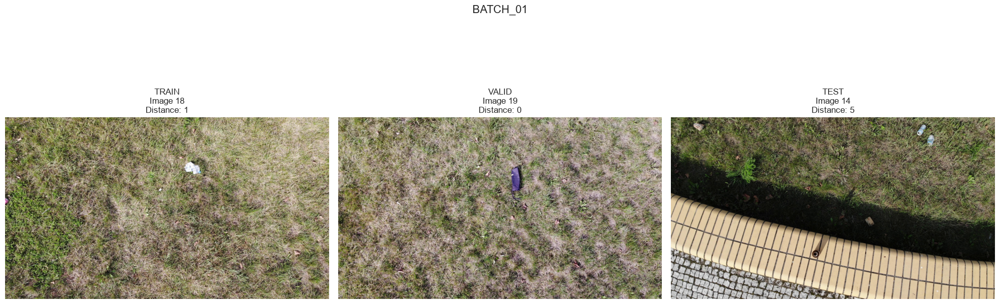

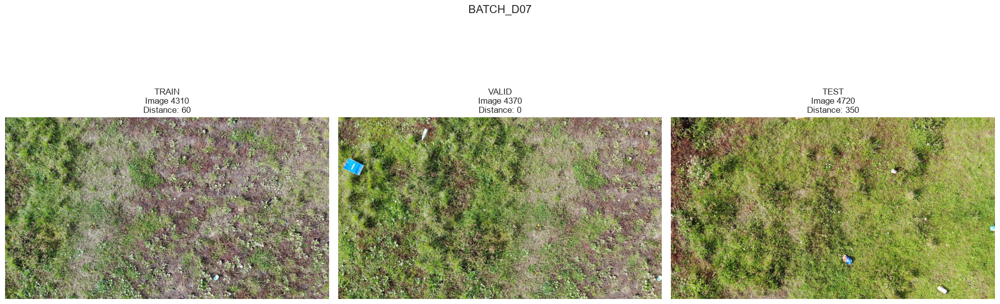

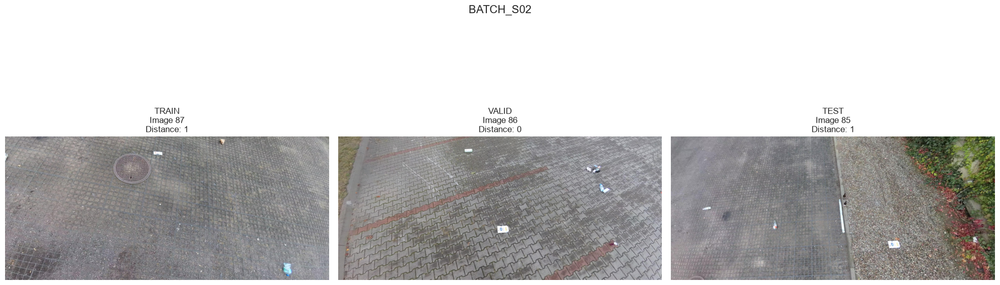

In [18]:
compare_batch_images("BATCH_01")
compare_batch_images("BATCH_D07")
compare_batch_images("BATCH_S02")

## 6. Final preprocessing decisions

Following the exploratory data analysis and acquisition group investigation, the original UCWD dataset is retained without modification.

### Decisions

- Preserve all original images and annotations.
- Retain the original training, validation and test splits.
- Preserve the seven original object categories.
- Retain annotations with negligible boundary deviations.

### Known limitations

Visual inspection confirmed spatial and temporal overlap between images belonging to different dataset splits.

This overlap may lead to optimistic model performance estimates and limit the assessment of generalization to independent acquisition sites.

The original dataset structure is retained to establish an initial detection baseline and ensure comparability with experiments using the original UCWD splits.

Group-based splitting and independent external validation are identified as potential directions for future work.